# Chapitre 1 - Exercices 1.7 à 1.12

Ce notebook traite les six derniers exercices du chapitre 1, centrés sur
l'architecture cloud native, le choix entre distribué et mono-nœud, et l'effacement des
données :

- **1.7** : dimensionner un cache local devant un object store (calcul et mini-lab) ;
- **1.8** : une machine ou un cluster ? (ordres de grandeur et métrique COST) ;
- **1.9** : réessais et idempotence, combien de doublons ? (probabilités et
  simulation) ;
- **1.10** : démarrages à froid et coût du serverless (calcul et simulation) ;
- **1.11** : l'intervalle optimal des points de reprise (démonstration et simulation) ;
- **1.12** : effacer dans un journal immuable, compaction ou crypto-shredding
  (calcul et mini-lab).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.sim import Network, Node

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 1.7 : dimensionner un cache local devant un object store

**Énoncé.** Un moteur analytique cloud native lit des blocs de 4 Mo. Lus depuis l'object
store, ils coûtent en moyenne 70 ms ; depuis le SSD local du nœud de calcul, 2 ms. Les
accès aux 100 000 blocs de l'entrepôt suivent une loi de Zipf d'exposant $s = 1{,}1$.

1. Quel taux de succès $h$ du cache faut-il pour que la lecture moyenne d'un bloc tombe
   sous 10 ms ?
2. Un cache **idéal** garderait les $C$ blocs les plus populaires. Exprimer son taux de
   succès en fonction de $C$, et en déduire la taille minimale.
3. Un vrai cache LRU fait moins bien. Trouver par simulation la taille nécessaire.
4. Chaque nœud a 1,9 To de SSD. Combien de nœuds faut-il au minimum pour que le cache
   réparti tienne, si chaque bloc est caché sur un seul nœud ?

**Rappels.** Lecture moyenne $= h\,L_{ssd} + (1 - h)\,L_{obj}$ ; loi de Zipf : la clé de
rang $i$ a une probabilité proportionnelle à $1/i^s$ ; cache LRU (`ar.LRUCache`), accès
Zipf (`ar.zipf_keys`) (cours 3, section 5 ; section *Separation of storage and compute*).

**Solution.**

*1.* $h \cdot 2 + (1 - h) \cdot 70 \le 10 \iff 68\,h \ge 60 \iff h \ge 0{,}882$.

*2.* Le cache idéal capture la masse des $C$ premiers rangs :
$h(C) = \sum_{i \le C} i^{-s} / \sum_{i \le N} i^{-s}$. On cherche le plus petit $C$ tel que
$h(C) \ge 0{,}882$ (calcul ci-dessous) : environ 8 700 blocs, moins de 9 % de l'entrepôt.
C'est la force de la loi de Zipf : une petite tête de blocs très populaires concentre
l'essentiel des accès.

*3.* La simulation (ci-dessous) donne une taille LRU environ deux fois plus grande, de
l'ordre de 18 000 blocs : LRU garde aussi des blocs peu populaires récemment lus, au
détriment de blocs plus populaires. (La courbe LRU plafonne vers 92 % : sur une trace
finie, le premier accès à chacun des nombreux blocs rares est un échec inévitable.)

*4.* 18 000 blocs de 4 Mo = 72 Go : un seul nœud suffit largement, son SSD de 1,9 To
pourrait même cacher tout l'entrepôt (400 Go). La vraie question devient alors : pourquoi
ne pas tout cacher ? Parce qu'un nouveau nœud (élasticité, remplacement après panne)
démarre à froid : le cache est un état éphémère qu'il faut réchauffer (cours 3).

**Vérification.**

h requis = 0.882 ; cache idéal : C = 8 731 blocs


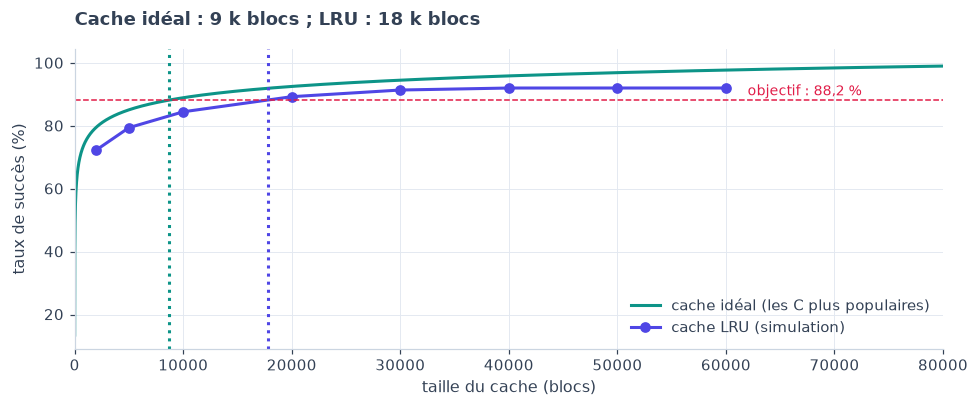

In [2]:
N, s, L_obj, L_ssd = 100_000, 1.1, 70.0, 2.0
h_target = (L_obj - 10) / (L_obj - L_ssd)
w = 1 / np.arange(1, N + 1) ** s
h_ideal = np.cumsum(w) / w.sum()
C_ideal = int(np.searchsorted(h_ideal, h_target)) + 1
print(f"h requis = {h_target:.3f} ; cache idéal : C = {fmt(C_ideal)} blocs")

trace = ar.zipf_keys(N, 400_000, s=s, seed=1)
sizes = [2_000, 5_000, 10_000, 20_000, 30_000, 40_000, 50_000, 60_000]
lru = []
for C in sizes:
    c = ar.LRUCache(C)
    for k in trace[:100_000]:                          # échauffement
        c.get(int(k))
    c.hits = c.misses = 0
    for k in trace[100_000:]:
        c.get(int(k))
    lru.append(c.hit_ratio)
C_lru = np.interp(h_target, lru, sizes)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.arange(1, N + 1), h_ideal * 100, color=TEAL, label="cache idéal (les C plus populaires)")
ax.plot(sizes, np.array(lru) * 100, "o-", color=INDIGO, label="cache LRU (simulation)")
ax.axhline(h_target * 100, color=ROSE, ls="--", lw=1); ax.text(62_000, h_target * 100 + 1.5, "objectif : 88,2 %", color=ROSE, fontsize=9)
ax.axvline(C_ideal, color=TEAL, ls=":"); ax.axvline(C_lru, color=INDIGO, ls=":")
ax.set_xlim(0, 80_000); ax.set_xlabel("taille du cache (blocs)"); ax.set_ylabel("taux de succès (%)")
ax.set_title(f"Cache idéal : {C_ideal / 1000:.0f} k blocs ; LRU : {C_lru / 1000:.0f} k blocs")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

Les deux tailles confirment le raisonnement : 9 % des blocs pour le cache idéal, le double
pour LRU. À 4 Mo par bloc, cela reste quelques dizaines de gigaoctets, qui tiennent
sans peine sur le SSD d'un seul nœud.

> **À retenir.** Le taux de succès requis se déduit des deux latences ; la taille du cache
> se déduit de la distribution des accès, et LRU demande environ deux fois la taille d'un
> cache idéal. Avec des accès concentrés (Zipf), quelques pour cent des données suffisent.

## Exercice 1.8 : une machine ou un cluster ?

**Énoncé.** Une équipe doit exécuter chaque heure une requête qui parcourt un historique
de 2 To au format colonne, dont la requête ne lit que 3 colonnes sur 30 (de tailles
égales), avec un taux de compression de 4 sur ces colonnes.

1. Combien d'octets la requête lit-elle sur disque ? Combien de temps prend-elle sur une
   machine dotée de 4 SSD NVMe à 3 Go/s chacun, si le processeur suit ?
2. Le processeur décompresse et agrège à 1,5 Go/s de données décompressées par cœur. Avec
   32 cœurs, qui limite : le disque ou le processeur ?
3. Un cluster de calcul lit les mêmes données depuis un object store, à 10 Gb/s de réseau
   par nœud, et son moteur générique fait 4 fois plus de travail processeur qu'un moteur
   mono-nœud optimisé. Combien de nœuds de 32 cœurs faut-il pour faire mieux que la
   machine unique ?
4. Un banc d'essai a mesuré pour le cluster : 1 nœud 410 s, 2 nœuds 215 s, 4 nœuds 118 s,
   8 nœuds 69 s, 16 nœuds 45 s, 32 nœuds 38 s. Le programme mono-nœud optimisé prend 50 s.
   Quelle est la COST du cluster (en nœuds) ?

**Rappels.** Métrique COST : plus petite configuration qui bat le programme mono-thread
(ici mono-nœud) de référence (`ar.cost_metric`) ; le débit d'un traitement est le minimum
des débits de ses étapes ; amener le calcul aux données (cours 4, section 3 ; section
*Problems with Distributed Systems*).

**Solution.**

*1.* 3 colonnes sur 30 : 200 Go décompressés, soit 50 Go compressés lus. À 12 Go/s :
**4,2 s** de lecture.

*2.* Processeur : 200 Go décompressés à $32 \times 1{,}5 = 48$ Go/s, soit **4,2 s**
également. Les deux sont équilibrés : environ 4 à 5 secondes par requête, une machine
suffit largement pour une requête par heure.

*3.* Par nœud : réseau 10 Gb/s = 1,25 Go/s compressés, soit 5 Go/s décompressés ;
processeur $48 / 4 = 12$ Go/s utiles. Le réseau limite à 5 Go/s par nœud. Pour battre
48 Go/s (le goulot de la machine unique, en équilibre avec ses disques), il faut au moins
$\lceil 48/5 \rceil = 10$ nœuds, soit 320 cœurs, sans compter la coordination.

*4.* Le premier temps inférieur à 50 s est celui de 16 nœuds (45 s) : **COST = 16 nœuds**.
Au-delà, le gain s'effondre (38 s à 32 nœuds) : la coordination domine.

**Vérification numérique** et graphique.

lu : 50 Go ; disque 4.2 s ; CPU 4.2 s ; cluster : 5 Go/s utiles par nœud -> 10 nœuds pour égaler
COST = 16 nœuds


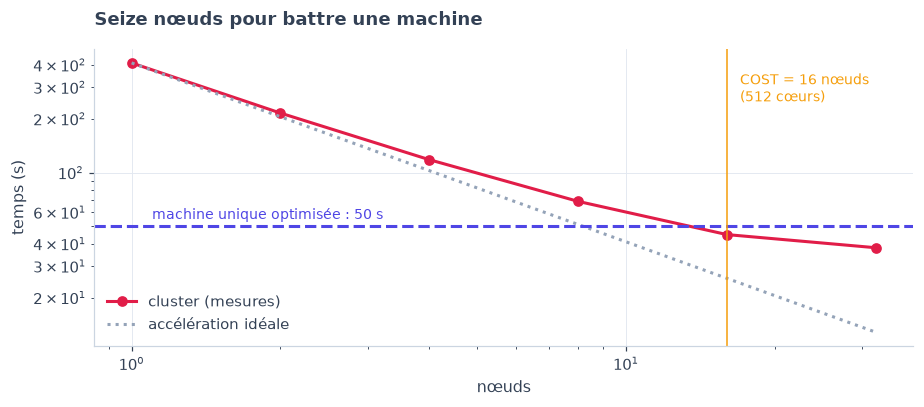

In [3]:
read_gb = 2000 * 3 / 30 / 4
t_disk = read_gb / (4 * 3)
t_cpu = 2000 * 3 / 30 / (32 * 1.5)
per_node = min(10 / 8 * 4, 32 * 1.5 / 4)
nodes_needed = math.ceil(32 * 1.5 / per_node)
print(f"lu : {read_gb:.0f} Go ; disque {t_disk:.1f} s ; CPU {t_cpu:.1f} s ; "
      f"cluster : {per_node:.0f} Go/s utiles par nœud -> {nodes_needed} nœuds pour égaler")
ns = [1, 2, 4, 8, 16, 32]
times = [410, 215, 118, 69, 45, 38]
print("COST =", ar.cost_metric(ns, times, 50), "nœuds")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.loglog(ns, times, "o-", color=ROSE, label="cluster (mesures)")
ax.loglog(ns, 410 / np.array(ns), ":", color=GRAY, label="accélération idéale")
ax.axhline(50, color=INDIGO, ls="--"); ax.text(1.1, 55, "machine unique optimisée : 50 s", color=INDIGO, fontsize=9)
ax.axvline(16, color=AMBER, lw=1); ax.text(17, 250, "COST = 16 nœuds\n(512 cœurs)", color=AMBER, fontsize=9)
ax.set_xlabel("nœuds"); ax.set_ylabel("temps (s)"); ax.set_title("Seize nœuds pour battre une machine")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

Il faut 512 cœurs répartis pour battre 32 cœurs bien employés : c'est l'ordre de grandeur
que la métrique COST met en évidence dans la littérature. La machine unique est aussi
beaucoup plus simple à exploiter.

> **À retenir.** Avant de distribuer, estimer ce que fait une seule machine bien utilisée
> (format colonne, compression, disques locaux rapides). Un cluster qui lit par le réseau
> avec un moteur générique doit d'abord rattraper son surcoût : sa COST se compte souvent en
> dizaines de nœuds.